# **TITLE : Analyze customer purchase behavior over time.**


**Problem Statement** : Analyze global apparel sales performance and customer purchase behavior across retail channels over time.

**Project ID** : CEP-78

**Roll No** : 160125737024

**Name of the Student** : Gukanti Bhavna



**Department of IT**


**Chaitanya Bharathi Institute of Technology**

**Problem Overview** : This project analyzes global apparel sales performance and customer purchasing behavior across different retail channels over time. It identifies sales trends, popular product categories, customer preferences, and regional performance. Data analysis and visualization help compare online and offline sales channels. The insights support better business decisions, improved customer satisfaction, and increased sales performance.


[**Data Set link**](https://docs.google.com/spreadsheets/d/1pG3R-2ZGnmhlUUkKPDMrfX5gQL_jbORjIXmOizR02oI/edit?usp=sharing)

*System Environment : *
*   **Version:** Python 3
*   **Libraries:** Numpy, Pandas, Matplotlib, Seaborn



In [ ]:
#importing necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#reading the file
df = pd.read_excel('/content/indian_apparel_online_shopping_enhanced_synthetic_dataset.xlsx')
print(df.columns)
print("\n--------------------------------------------------\n")
#preview of the dataset
df.head()
#shape
df.shape

Index(['Customer ID', 'Order ID', 'Transaction Date', 'Age', 'Gender',
       'Item Purchased', 'Category', 'Fashion Brand', 'Purchase Amount (INR)',
       'Quantity', 'Unit Price (INR)', 'Revenue (INR)', 'Location',
       'Retail Store Region', 'Size', 'Color', 'Season', 'Review Rating',
       'Subscription Status', 'Payment Method', 'Preferred Payment Method',
       'Shipping Type', 'Delivery Days', 'Discount Applied', 'Promo Code Used',
       'Product Discount (%)', 'Previous Purchases', 'Frequency of Purchases',
       'Customer Segment', 'Device Type', 'Order Status', 'Return Status',
       'Transaction Month'],
      dtype='object')

--------------------------------------------------



(150, 33)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



# **Q1: Calculate total revenue per fashion brand category using numpy (BL-3)**

In [ ]:
category = "Category"
revenue = "Purchase Amount (INR)"

df[revenue] = pd.to_numeric(df[revenue], errors="coerce")
categories = df[category].dropna().unique()

for c in categories:
  total = np.sum(df.loc[df[category] == c, revenue].dropna())
  print(c, ":", total)

Ethnic Wear : 66120
Western Wear : 54110
Sportswear : 49830
Casual Wear : 41550
Formal Wear : 117300


# **Q2: Filter clothing transaction data by apparel size and customer gender (BL-3)**

Condition 1 (df["Size"] == "M"): This checks every row in the "Size" column to find matches where the apparel size is Medium ("M"), returning a Series of True and False values.

Condition 2 (df["Gender"] == "Female"): This checks the "Gender" column for rows where the customer gender is "Female", also returning a boolean Series.

Combining with Bitwise AND (&): The & operator combines both conditions so that a row is selected only if both statements are True. Parentheses are required around each condition because of operator precedence in Python.

Filtering the DataFrame (df[...]): Passing the combined boolean mask back into the DataFrame (df[...]) filters out all rows that do not meet both criteria, leaving only the matching subset which is then stored in filtered_data.

In [ ]:
filtered_data = df[
    (df["Size"] == "M") &
    (df["Gender"] == "Female")
]

print("\n---------------Filtered Data by Size and Gender------------\n")
print(filtered_data)


---------------Filtered Data by Size and Gender------------

    Customer ID  Order ID Transaction Date  Age  Gender  Item Purchased  \
3       CUST004  ORD00004       2025-11-23   21  Female  Sports T-shirt   
16      CUST017  ORD00017       2025-02-10   39  Female         T-shirt   
37      CUST038  ORD00038       2025-10-12   44  Female  Sports T-shirt   
53      CUST054  ORD00054       2025-07-23   44  Female           Kurti   
74      CUST075  ORD00075       2025-08-28   28  Female           Kurti   
75      CUST076  ORD00076       2025-04-03   23  Female        Leggings   
103     CUST104  ORD00104       2025-01-24   42  Female    Formal Dress   
131     CUST132  ORD00132       2025-11-06   27  Female     Track Pants   
138     CUST139  ORD00139       2025-05-18   54  Female           Jeans   
141     CUST142  ORD00142       2025-03-09   52  Female           Dress   

         Category Fashion Brand  Purchase Amount (INR)  Quantity  ...  \
3      Sportswear          Puma        

# **Q3: Handle missing discount and promotional code data fields (BL-4)**

In [ ]:
# Q3: Handle missing discount and promotional code data fields (BL-4)

missing = df["Discount Applied"].isnull().sum()
print("Missing values:", missing)

# Printing the rows where discount is missing
print(df[df["Discount Applied"].isna()].head(10))

# Fill numeric columns with the mean
df["Product Discount (%)"] = df["Product Discount (%)"].fillna(df["Product Discount (%)"].mean())

print(df["Product Discount (%)"])


Missing values: 10
    Customer ID  Order ID Transaction Date  Age             Gender  \
5       CUST006  ORD00006       2025-03-29   18  Prefer not to say   
12      CUST013  ORD00013       2025-08-09   24             Female   
24      CUST025  ORD00025       2025-09-07   27             Female   
53      CUST054  ORD00054       2025-07-23   44             Female   
62      CUST063  ORD00063       2025-10-04   33  Prefer not to say   
82      CUST083  ORD00083              NaT   48               Male   
83      CUST084  ORD00084       2025-09-08   35             Female   
94      CUST095  ORD00095       2025-07-27   42               Male   
134     CUST135  ORD00135              NaT   48               Male   
147     CUST148  ORD00148       2025-03-03   23             Female   

     Item Purchased     Category  Fashion Brand  Purchase Amount (INR)  \
5             Shirt  Casual Wear       Westside                   1240   
12            Shirt  Casual Wear     Pantaloons               

# **Q4: Group sales data by clothing category and retail store region (BL-4)**


In [ ]:
category_region_sales = (
    df.groupby(["Category", "Location"])["Purchase Amount (INR)"].sum().reset_index()
)

# Rename the total column for clear presentation
category_region_sales = category_region_sales.rename(columns={"Purchase Amount (INR)": "Total Sales"})

print(category_region_sales)

# Create a cross-tabulated summary
sales_pivot = category_region_sales.pivot(
    index="Category",
    columns="Location",
    values="Total Sales"
).fillna(0)

print(sales_pivot)

        Category                       Location  Total Sales
0    Casual Wear             Ahmedabad, Gujarat         1240
1    Casual Wear           Bengaluru, Karnataka         3420
2    Casual Wear         Bhopal, Madhya Pradesh         1220
3    Casual Wear            Chennai, Tamil Nadu         4020
4    Casual Wear                          Delhi         4410
..           ...                            ...          ...
57  Western Wear         Lucknow, Uttar Pradesh         2550
58  Western Wear            Mumbai, Maharashtra          590
59  Western Wear                   Patna, Bihar         5400
60  Western Wear              Pune, Maharashtra         4440
61  Western Wear  Visakhapatnam, Andhra Pradesh         2700

[62 rows x 3 columns]
Location      Ahmedabad, Gujarat  Bengaluru, Karnataka  \
Category                                                 
Casual Wear               1240.0                3420.0   
Ethnic Wear                  0.0               12720.0   
Formal Wear  

#**Q5: Visualize monthly sales volume trends using line plots and box plots(BL-5)**

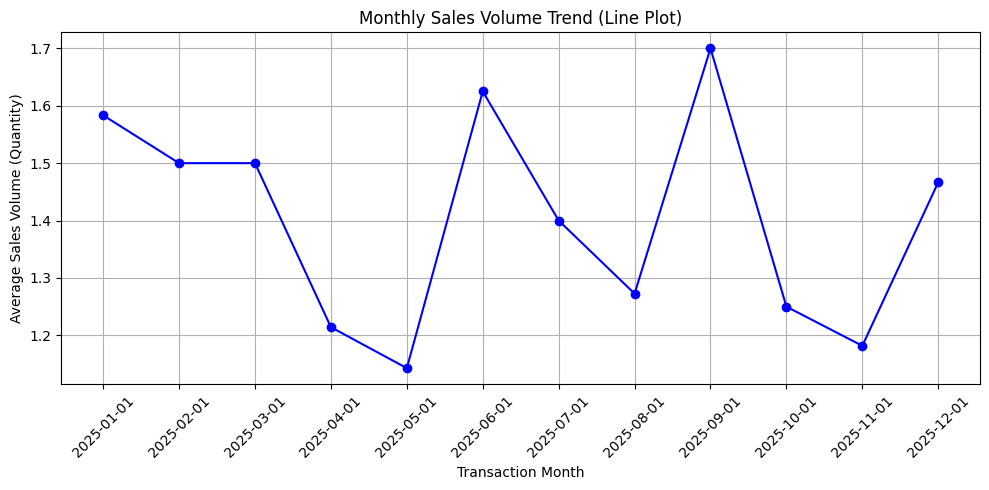

/tmp/ipykernel_2659/1875123990.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


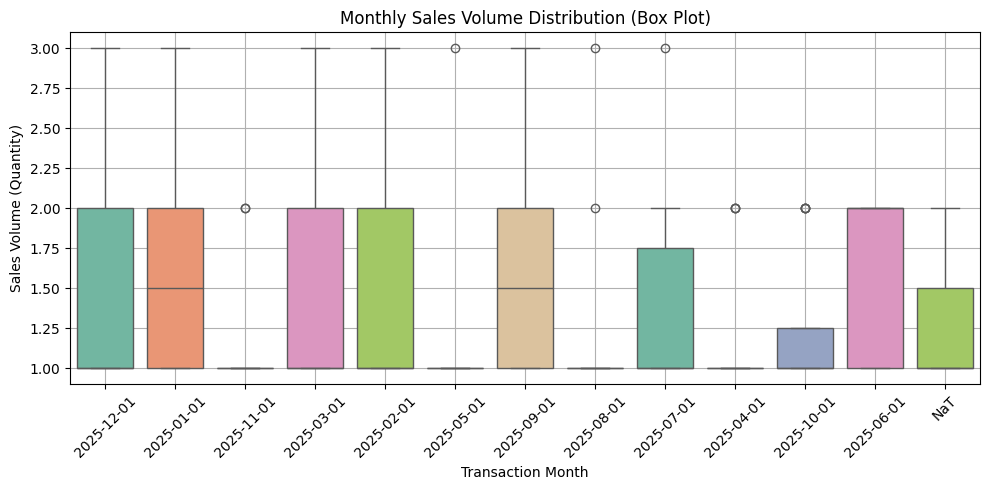

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average monthly sales volume trend
monthly_sales = df.groupby("Transaction Month")["Quantity"].mean()

# --- 1. Line Plot ---
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linestyle="-",
    color="b"
)
plt.title("Monthly Sales Volume Trend (Line Plot)")
plt.xlabel("Transaction Month")
plt.ylabel("Average Sales Volume (Quantity)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# --- 2. Box Plot ---
plt.figure(figsize=(10, 5))
sns.boxplot(
    x=df["Transaction Month"].astype(str),
    y=df["Quantity"],
    palette="Set2"
)
plt.title("Monthly Sales Volume Distribution (Box Plot)")
plt.xlabel("Transaction Month")
plt.ylabel("Sales Volume (Quantity)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()